# Manual-validation report — intake/outcome summary + inter-rater agreement

CSV-native and offline: reads only the published `data/validation/` exports
(`verdicts_raters.csv`, `manual_validation_final.csv`, `disagreement_resolutions.csv`)
— no SQLite dependency. This notebook is a **report** (display only); it writes no
artifacts. It covers (1) what entered validation and what came out (incl. the human
Safe-Refactor Rate, SRR), (2) inter-rater agreement (Cohen's κ), and (3) the
disagreement worklist that went to adjudication.

In [1]:
from IPython.display import display

from utils import validation_summary as vs, inter_rater as ir

## 1. What entered / what came out

In [2]:
s = vs.summarize()
h = s['headline']
print(f"judged={h['judged_instances']}  positives={h['positives']}  negatives={h['negatives']}  "
      f"gkeys={h['gkeys']}")
print(f"resolved disagreements={h['resolved_disagreements']}  adjudicated={h['adjudicated_instances']}  "
      f"unanimous={h['unanimous_instances']}")
print(f"SRR={h['SRR']}  SRR (excl. uncertain)={h['SRR_excl']}")

display(s['intake'])
display(s['srr_by_design'])

judged=1952  positives=1841  negatives=111  gkeys=1286
resolved disagreements=152  adjudicated=141  unanimous=1811
SRR=0.958  SRR (excl. uncertain)=0.979


,item,count
0,judged instances (stems),1952
1,GT-positive,1841
2,GT-negative,111
3,derivation groups (gkey),1286
4,validators,6
5,disagreements resolved (gkey),152
6,adjudicated instances,141
7,unanimous instances,1811


,design,n,removed,uncertain,SRR,SRR_excl
0,D1,902,859,21,0.952,0.975
1,D2,939,905,18,0.964,0.983


In [3]:
display(s['positive_outcomes'])
display(s['negative_outcomes'])
display(s['construct_ok'])
display(s['potential_behavior_impact'])
display(s['resolution_source'])

,label,n,pct
0,removed,1764,95.8
1,not removed,38,2.1
2,uncertain,39,2.1


,label,n,pct
0,unnecessary,93,83.8
1,necessary,3,2.7
2,uncertain,9,8.1
3,preserved,6,5.4


,label,n,pct
0,yes,1753,95.2
1,no,23,1.2
2,uncertain,65,3.5


,label,n,pct
0,no,1766,90.5
1,yes,136,7.0
2,uncertain,44,2.3


,label,n,pct
0,unanimous,1811,92.8
1,adjudicated,141,7.2


## 2. Inter-rater agreement (Cohen's $\kappa$)

In [4]:
agr = ir.agreement_summary()
agr.round(4)

,dupla,co_judged,agreement_pct,kappa_verdict,kappa_potential_behavior_impact,kappa_construct,kappa_edit_type,kappa_combined
0,R1 & R2,449,91.76,0.5844,0.5601,0.9264,0.9056,0.6076
1,R3 & R4,421,89.31,0.7686,0.2133,0.9006,0.8821,0.7290
2,R5 & R6,462,93.51,0.7307,0.8951,0.9873,0.7010,0.8468
3,OVERALL,1332,91.59,NaN,NaN,NaN,NaN,0.7595


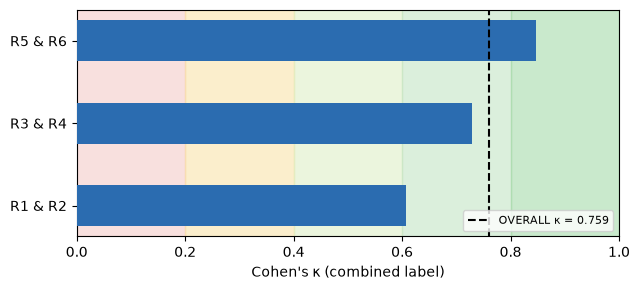

In [5]:
import matplotlib.pyplot as plt

per = agr[agr['dupla'] != 'OVERALL']
overall = float(agr.loc[agr['dupla'] == 'OVERALL', 'kappa_combined'].iloc[0])

# Landis & Koch bands behind the bars.
bands = [(0.0, 0.20, '#f4c7c3'), (0.20, 0.40, '#f9e0a2'), (0.40, 0.60, '#dceec1'),
         (0.60, 0.80, '#bfe3c0'), (0.80, 1.00, '#9ed7a3')]
fig, ax = plt.subplots(figsize=(6.5, 3))
for lo, hi, c in bands:
    ax.axvspan(lo, hi, color=c, alpha=0.55, zorder=0)
ax.barh(per['dupla'], per['kappa_combined'], color='#2b6cb0', height=0.5, zorder=3)
ax.axvline(overall, color='black', ls='--', zorder=4, label=f'OVERALL κ = {overall:.3f}')
ax.set_xlim(0, 1)
ax.set_xlabel("Cohen's κ (combined label)")
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 3. Disagreements (reconciliation worklist)

In [6]:
dis = ir.disagreements()
print(f'{len(dis)} disagreeing gkeys')
dis.head(15)

112 disagreeing gkeys


,dupla,gkey,fields,gt_positive,R1_verdict,R2_verdict,v1_potential_behavior_impact,v2_potential_behavior_impact,v1_third,v2_third,R3_verdict,R4_verdict,R5_verdict,R6_verdict
0,R1 & R2,055721dd94d36751a2ef190a368370c851adfa38700315...,verdict,False,uncertain,necessary,no,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
1,R1 & R2,0f85e2c88a22e641dc96b79bc1ebed0ddadae6709ac527...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
2,R1 & R2,15ad747628f4e8ca8541ad5eb672a65d4184ff260f3865...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
3,R1 & R2,17ff513d2674deb20d2ae5eb9e41a091cc043749e9840c...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
4,R1 & R2,195f50bd559df55865c55d64f32a030838bfc5ed28befe...,"potential_behavior_impact, construct_ok",True,removed,removed,yes,no,no,yes,NaN,NaN,NaN,NaN
5,R1 & R2,1af3b00c72572fb2cb130d3e187d6771b424a4d6d3210b...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
6,R1 & R2,21f4f7cce0ffd4298db7c66b42113f69efeb9525070682...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
7,R1 & R2,4725e2577754d96b3770c026aa181b2d516aaa250aca2d...,potential_behavior_impact,True,removed,removed,no,uncertain,yes,yes,NaN,NaN,NaN,NaN
8,R1 & R2,4a11d223b810c970d3f57be7decf335b98f70902376771...,"verdict, edit_type",False,unnecessary,necessary,no,no,localized but unnecessary edits,behavior-relevant edits,NaN,NaN,NaN,NaN
9,R1 & R2,5adcff98dba3c3576eb452281e5d1bc18a785cfa2ff4fd...,"verdict, potential_behavior_impact",False,unnecessary,necessary,yes,no,behavior-relevant edits,behavior-relevant edits,NaN,NaN,NaN,NaN
